In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
DATA_PATH = "/content/drive/MyDrive/CMP6202/datasets/"

df = pd.read_csv(DATA_PATH + "california.csv")

print("Shape:", df.shape)
df.head()

Shape: (6000, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,3.9263,36.0,6.070350,1.157718,1115.0,3.374284,36.10,-119.78,2.6341
1,4.9844,40.0,4.698557,1.197840,937.0,5.473621,33.63,-120.54,2.4793
2,3.5519,36.0,5.065780,1.163153,716.0,2.494249,36.38,-119.23,2.5199
3,3.2641,22.0,4.905804,0.885663,781.0,1.894566,40.96,-120.98,1.9243
4,5.3225,32.0,3.870211,1.166106,791.0,4.895304,35.87,-119.96,3.5996


In [ ]:
print(df.isnull().sum())
df.describe()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,3.683900,26.778167,5.240578,1.064893,1584.426833,2.846454,35.743565,-119.544633,2.306475
std,2.051020,14.983648,1.352537,0.149224,1365.053296,0.942399,1.990785,1.629923,1.072650
min,0.500000,1.000000,2.000000,0.555371,81.000000,1.000000,32.500000,-124.400000,0.150000
25%,2.193875,14.000000,4.313719,0.964537,719.000000,2.173094,34.240000,-120.640000,1.522650
50%,3.319450,27.000000,5.183799,1.063343,1189.000000,2.703265,35.660000,-119.510000,2.193250
75%,4.761675,40.000000,6.088437,1.160867,1977.500000,3.357416,37.110000,-118.410000,2.971350
max,15.000000,52.000000,12.350665,1.713667,12000.000000,8.000000,42.000000,-114.180000,5.000000


In [ ]:
(df['MedHouseVal']==5).sum()

np.int64(137)

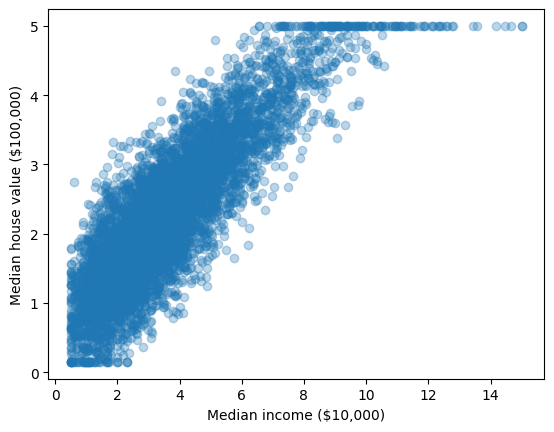

MedInc         0.86
HouseAge       0.07
AveRooms       0.65
AveBedrms      0.33
Population     0.03
AveOccup      -0.12
Latitude       0.11
Longitude     -0.18
MedHouseVal    1.00
Name: MedHouseVal, dtype: float64


In [ ]:
plt.scatter(df["MedInc"], df["MedHouseVal"], alpha=0.3)
plt.xlabel("Median income ($10,000)")
plt.ylabel("Median house value ($100,000)")
plt.show()

print(df.corr()["MedHouseVal"].round(2))

In [ ]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (4800, 8)
X_test: (1200, 8)


In [ ]:
results = {}

In [ ]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_base)
rmse = mean_squared_error(y_test, y_pred_base)
r2 = r2_score(y_test, y_pred_base)

results["Mean Baseline"] = [mae, rmse, r2]
print("MAE :", round(mae, 3))
print("RMSE :", round(rmse, 3))
print("R2 :"), round(r2, 3)

MAE : 0.865
RMSE : 1.151
R2 :


(None, -0.0)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lin = LinearRegression()
lin.fit(X_train_scaled, y_train)
y_pred_lin = lin.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred_lin)
rmse = mean_squared_error(y_test, y_pred_lin)
r2 = r2_score(y_test, y_pred_lin)

results["Linear Regression"] = [mae, rmse, r2]
print("MAE :", round(mae, 3))
print("RMSE :", round(rmse, 3))
print("R2 :"), round(r2, 3)

MAE : 0.386
RMSE : 0.242
R2 :


(None, 0.79)

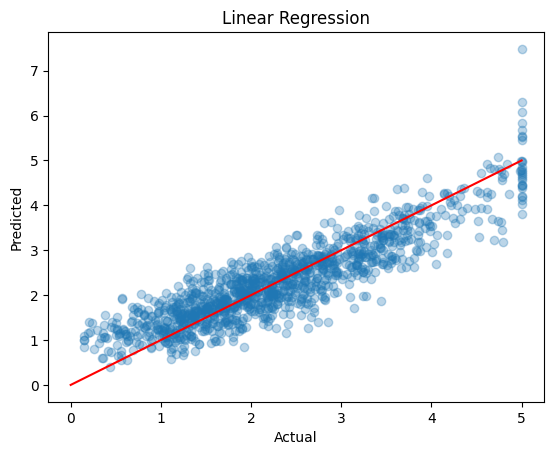

In [ ]:
plt.scatter(y_test, y_pred_lin, alpha=0.3)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Linear Regression")
plt.show()

In [ ]:
tree = DecisionTreeRegressor(max_depth=8, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_tree)
rmse = mean_squared_error(y_test, y_pred_tree) ** 0.5
r2 = r2_score(y_test, y_pred_tree)

results["Decision Tree"] = [mae, rmse, r2]
print("MAE :", round(mae, 3))
print("RMSE :", round(rmse, 3))
print("R2 :"), round(r2, 3)

MAE : 0.428
RMSE : 0.535
R2 :


(None, 0.751)

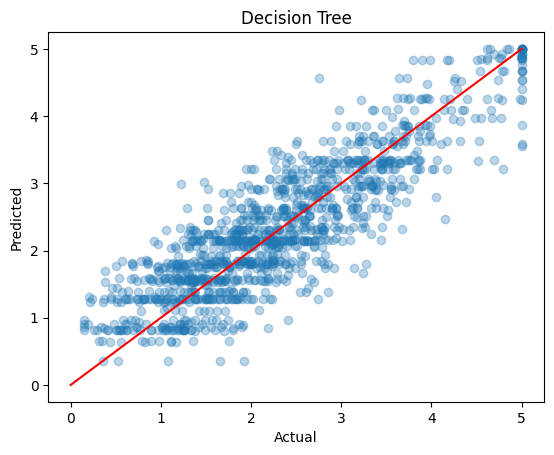

In [ ]:
plt.scatter(y_test, y_pred_tree, alpha=0.3)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Decision Tree")
plt.show()

In [ ]:
forest = RandomForestRegressor(n_estimators=200, random_state=42)
forest.fit(X_train, y_train)
y_pred_rf = forest.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_rf)
rmse = mean_squared_error(y_test, y_pred_rf) ** 0.5
r2 = r2_score(y_test, y_pred_rf)

results["Random Forest"] = [mae, rmse, r2]
print("MAE :", round(mae, 3))
print("RMSE :", round(rmse, 3))
print("R2 :"), round(r2, 3)

MAE : 0.381
RMSE : 0.481
R2 :


(None, 0.799)

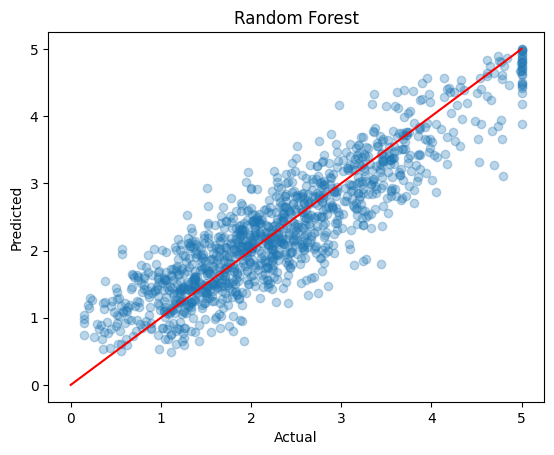

In [ ]:
plt.scatter(y_test, y_pred_rf, alpha=0.3)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Random Forest")
plt.show()

In [ ]:
comparison = pd.DataFrame(results, index=["MAE", "RMSE", "R2"]).T.round(3)
comparison

,MAE,RMSE,R2
Mean Baseline,0.865,1.151,-0.000
Linear Regression,0.386,0.242,0.790
Decision Tree,0.428,0.535,0.751
Random Forest,0.381,0.481,0.799


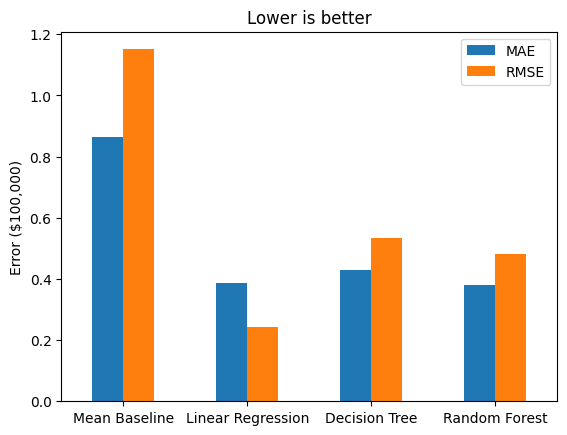

In [ ]:
comparison[["MAE", "RMSE"]].plot(kind="bar", rot=0)
plt.ylabel("Error ($100,000)")
plt.title("Lower is better")
plt.show()